# 05 · Comparer les approches et choisir

*Module 14 « Feature engineering & transformation » · TD du mercredi 21 octobre 2026 · environ 20 minutes en salle.*

### Ce qu'on fait

Les notebooks 01 à 04 ont écrit leurs scores dans `output/` : six préparations (A, B, C1, C2, C3, D) × cinq
modèles, sur le même découpage et avec les mêmes métriques. On les met côte à côte, on les lit famille de modèles
par famille, on choisit un modèle, puis on le confronte à de nouvelles réservations, dont un pays et un agent
jamais vus. On finit par ce que cette comparaison ne dit pas.

### Les choix de cette approche

| Décision | Choix | Pourquoi |
|---|---|---|
| Ce qu'on compare | les 30 lignes de `output/resultats_*.csv`, sans rien réentraîner | même découpage, mêmes modèles, mêmes métriques : seule la préparation change |
| Critère principal | l'AUC ROC sur le test ; puis la précision moyenne et l'exactitude au seuil 0,5 | l'AUC juge le classement des réservations, sans choisir de seuil (notebook 00) |
| Grille de lecture | par famille de modèles : linéaire, distances, réseau, arbres | la bonne préparation dépend du modèle : c'est la fiche réflexe du cours 2 |
| Coût | la durée (entraînement + prédiction) et le nombre de colonnes | chaque variable a un coût : du calcul, du code à maintenir, une valeur à servir |
| Courbes | ROC du meilleur modèle de chaque approche, relues dans `output/probas_*.parquet` | comparer des classements entiers, pas seulement un nombre |
| Modèle retenu | le gradient boosting de B, rechargé depuis `output/modele_B.joblib` | meilleure AUC ; l'objet contient toute la préparation |
| Mise à l'épreuve | trois nouvelles réservations, dont un pays (`XKX`) et un agent (`999`) jamais vus | le modèle doit survivre à la production, pas seulement au test |
| Limites | AUC mois par mois, intervalle par bootstrap, autres graines aléatoires | un seul découpage, un seul échantillon de test, un seul tirage |

### Les outils utilisés

- `pandas` : `pd.concat`, `pivot`, `idxmax`, `groupby` pour empiler et croiser les résultats.
- `matplotlib` : `imshow` (carte de chaleur), `scatter`, `plot`.
- `roc_curve` et `roc_auc_score` (`sklearn.metrics`) : courbes ROC et AUC, comme au notebook 00.
- La fiche réflexe : quatre familles de modèles, trois décisions de préparation (cours 2, slide 28) ; « chaque
  variable a un coût » (cours 2, slide 17).
- `joblib.load` : recharger l'objet entier, préparation comprise (cours 2, slides 24 et 25).
- `variables_metier` (`fe_tp.variables`) et l'historique à date : le passé, rien que le passé (cours 1, slides 13
  et 14).
- `OneHotEncoder(handle_unknown="infrequent_if_exist")`, `TargetEncoder` et `SimpleImputer(add_indicator=True)`
  face aux modalités jamais vues (cours 1, slides 18, 21 et 22).
- `numpy.random.default_rng` (bootstrap), `clone` et `StratifiedKFold` (autres graines aléatoires).

### Ce qu'on regarde à la fin

La carte de chaleur des 30 AUC et le modèle retenu ; ses probabilités pour trois nouvelles réservations ; et
l'incertitude qui entoure les écarts entre approches.

## 1. Rassembler les résultats

Chaque appel à `evaluer` a écrit un fichier `output/resultats_<code>.csv` : une ligne par modèle. On les empile.
On recharge aussi les données, pour deux usages seulement : vérifier la cible du test et fabriquer, plus loin, de
nouvelles réservations.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold

from fe_tp.donnees import CIBLE, FUITES, SORTIES, charger, decouper
from fe_tp.evaluation import FAMILLES
from fe_tp.variables import variables_metier

BLEU, ORANGE = "#0B3C7D", "#E8A33D"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
df = charger()
train, test = decouper(df)
fichiers = sorted(SORTIES.glob("resultats_*.csv"))
resultats = pd.concat([pd.read_csv(f) for f in fichiers], ignore_index=True)
resultats["code"] = resultats["approche"].str.split(" · ").str[0]
print(len(fichiers), "fichiers,", len(resultats), "lignes :", ", ".join(f.name for f in fichiers))
resultats.groupby("approche").agg(colonnes=("nb_variables", "first"), duree_totale_s=("duree_s", "sum"),
                                  auc_max=("auc", "max")).round(3)

6 fichiers, 30 lignes : resultats_A.csv, resultats_B.csv, resultats_C1.csv, resultats_C2.csv, resultats_C3.csv, resultats_D.csv


,colonnes,duree_totale_s,auc_max
approche,,,
A · strict minimum,365,104.530,0.873
B · variables métier,83,90.954,0.888
C1 · interactions + ACP,95,99.961,0.819
C2 · interactions + filtre,40,65.041,0.826
C3 · interactions + L1,182,184.534,0.867
D · arbres natifs,25,118.909,0.870


Six fichiers, trente lignes. Les préparations n'ont ni la même taille ni le même coût : de 25 colonnes (D) à
365 (A), et d'environ 65 s (C2) à environ 185 s (C3) pour entraîner et interroger les cinq modèles. La meilleure
AUC va de 0,819 (C1) à 0,888 (B). Le tableau croisé, une ligne par approche et une colonne par modèle :

In [3]:
MODELES = list(FAMILLES)
auc = resultats.pivot(index="approche", columns="modele", values="auc")[MODELES]
auc.round(3)

modele,Régression logistique,kNN,Réseau de neurones,Forêt aléatoire,Gradient boosting
approche,,,,,
A · strict minimum,0.853,0.817,0.854,0.870,0.873
B · variables métier,0.851,0.853,0.881,0.888,0.888
C1 · interactions + ACP,0.795,0.743,0.819,0.789,0.807
C2 · interactions + filtre,0.808,0.803,0.815,0.819,0.826
C3 · interactions + L1,0.845,0.762,0.850,0.837,0.867
D · arbres natifs,0.786,0.719,0.792,0.852,0.870


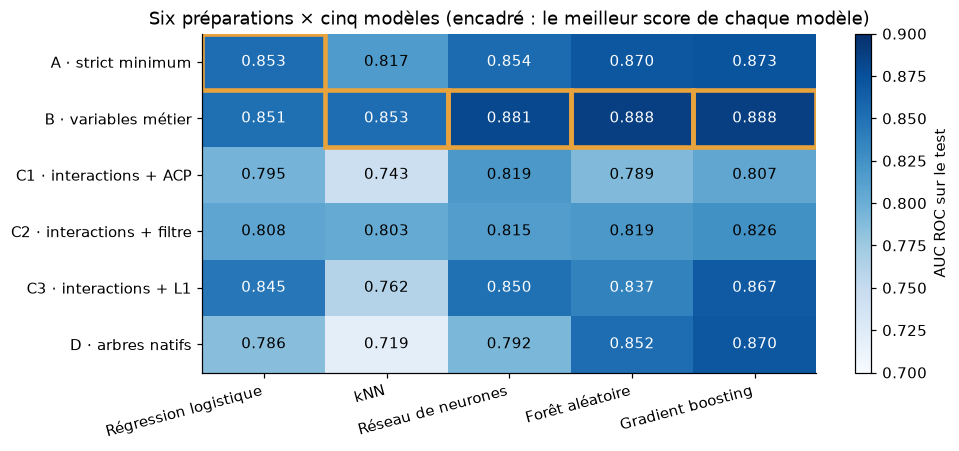

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
image = ax.imshow(auc, cmap="Blues", vmin=0.70, vmax=0.90, aspect="auto")
for (i, j), valeur in np.ndenumerate(auc.to_numpy()):
    ax.text(j, i, f"{valeur:.3f}", ha="center", va="center", color="white" if valeur > 0.83 else "black")
for j, i in enumerate(np.argmax(auc.to_numpy(), axis=0)):
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=ORANGE, linewidth=3))
ax.set_xticks(range(len(MODELES)), MODELES, rotation=15, ha="right")
ax.set_yticks(range(len(auc)), auc.index)
fig.colorbar(image, label="AUC ROC sur le test")
ax.set_title("Six préparations × cinq modèles (encadré : le meilleur score de chaque modèle)")
plt.show()

La ligne B est la plus foncée : quatre modèles sur cinq y obtiennent leur meilleur score (cases encadrées : kNN
0,853, réseau 0,881, forêt et boosting 0,888). Seule la régression logistique fait un peu mieux en A (0,853 contre 0,851). Les
lignes C1 (ACP) et C2 (filtre) sont les plus claires : toutes leurs cases sont sous 0,83. La ligne D est
contrastée : foncée pour les deux arbres (0,852 et 0,870), claire pour les trois autres modèles (de 0,719 à 0,792).

## 2. Lire par famille de modèles

Première question : que rapporte chaque approche par rapport au strict minimum (A), modèle par modèle ? On
retranche la ligne A à chaque ligne.

In [5]:
(auc - auc.loc["A · strict minimum"]).round(3)

modele,Régression logistique,kNN,Réseau de neurones,Forêt aléatoire,Gradient boosting
approche,,,,,
A · strict minimum,0.000,0.000,0.000,0.000,0.000
B · variables métier,-0.002,0.036,0.026,0.017,0.015
C1 · interactions + ACP,-0.058,-0.074,-0.035,-0.081,-0.066
C2 · interactions + filtre,-0.045,-0.014,-0.040,-0.051,-0.047
C3 · interactions + L1,-0.008,-0.056,-0.004,-0.033,-0.005
D · arbres natifs,-0.067,-0.098,-0.062,-0.018,-0.003


B est la seule approche qui gagne sur quatre modèles : +0,036 pour le kNN, +0,026 pour le réseau, +0,017 pour
la forêt, +0,015 pour le boosting ; la régression logistique perd 0,002. Toutes les variantes C perdent partout,
de −0,004 (réseau, C3) à −0,081 (forêt, C1). D ne coûte presque rien au boosting (−0,003) mais beaucoup au kNN
(−0,098). Deuxième question : pour chaque modèle, quelle préparation lui convient le mieux, et laquelle le
moins ?

In [6]:
pd.DataFrame({"famille": pd.Series(FAMILLES), "meilleure préparation": auc.idxmax(), "AUC max": auc.max(),
              "pire préparation": auc.idxmin(), "AUC min": auc.min(),
              "écart": auc.max() - auc.min()}).round(3)

,famille,meilleure préparation,AUC max,pire préparation,AUC min,écart
Régression logistique,linéaire,A · strict minimum,0.853,D · arbres natifs,0.786,0.067
kNN,distances,B · variables métier,0.853,D · arbres natifs,0.719,0.134
Réseau de neurones,réseau,B · variables métier,0.881,D · arbres natifs,0.792,0.089
Forêt aléatoire,arbres,B · variables métier,0.888,C1 · interactions + ACP,0.789,0.098
Gradient boosting,arbres,B · variables métier,0.888,C1 · interactions + ACP,0.807,0.081


Le kNN est le plus sensible à la préparation : 0,134 d'écart entre B (0,853) et D (0,719). La régression
logistique l'est le moins (0,067, de 0,853 en A à 0,786 en D). Les trois familles qui calculent sur les valeurs
elles-mêmes (linéaire, distances, réseau) ont leur pire score en D ; les deux arbres, en C1. On retrouve, chiffrée, la fiche réflexe du
cours 2 (slide 28) :

| Famille | Fiche réflexe | Ce que disent nos chiffres |
|---|---|---|
| Linéaire (régression logistique) | mise à l'échelle nécessaire ; one-hot ou encodage par la cible ; Lasso utile | one-hot (A) 0,853 ≈ encodage par la cible (B) 0,851 ≈ L1 (C3) 0,845 ; codes entiers sans échelle (D) 0,786 |
| Distances (kNN) | mise à l'échelle indispensable ; one-hot ; sélection très utile | 83 colonnes standardisées (B) 0,853 ; 365 colonnes (A) 0,817 ; échelles brutes (D) 0,719 ; parmi les C, les 40 colonnes du filtre (0,803) battent les 182 de la L1 (0,762) |
| Réseau de neurones | mise à l'échelle indispensable ; one-hot ou plongements | B 0,881, A 0,854, D 0,792 |
| Arbres (forêt, boosting) | mise à l'échelle inutile ; ordinal ou support natif | boosting sur 25 codes (D) 0,870 ≈ sur 365 colonnes (A) 0,873 ; B 0,888 ; l'ACP (C1) les fait chuter à 0,789 et 0,807 |

> 💬 **Pour la salle.** Pourquoi le kNN est-il, de loin, le modèle le plus sensible à la préparation ?
>
> *Piste : il ne fait que mesurer des distances, et chaque colonne y pèse selon son échelle. Sans mise à l'échelle
> (D), `lead_time`, qui monte à 737 jours, écrase tout ; avec 365 colonnes (A), les distances se ressemblent
> (fléau de la dimension, cours 2, slide 11). B lui donne peu de colonnes, toutes à la même échelle, et résume
> chaque agent et chaque pays en une seule colonne (encodage par la cible).*

## 3. Le meilleur modèle de chaque approche : autres métriques et coût

Pour chaque approche, on garde le modèle qui a la meilleure AUC, et on regarde ses autres mesures.

In [7]:
meilleurs = resultats.loc[resultats.groupby("approche")["auc"].idxmax()].set_index("approche")
meilleurs = meilleurs[["code", "modele", "auc", "precision_moyenne", "exactitude", "nb_variables", "duree_s"]]
meilleurs.round(3)

,code,modele,auc,precision_moyenne,exactitude,nb_variables,duree_s
approche,,,,,,,
A · strict minimum,A,Gradient boosting,0.873,0.834,0.778,365,8.479
B · variables métier,B,Gradient boosting,0.888,0.853,0.797,83,8.435
C1 · interactions + ACP,C1,Réseau de neurones,0.819,0.787,0.750,95,24.676
C2 · interactions + filtre,C2,Gradient boosting,0.826,0.794,0.751,40,3.282
C3 · interactions + L1,C3,Gradient boosting,0.867,0.829,0.770,182,23.442
D · arbres natifs,D,Gradient boosting,0.870,0.832,0.774,25,2.584


Le gradient boosting est le meilleur modèle de cinq approches sur six ; seule l'ACP (C1) lui préfère le réseau de
neurones. Les trois mesures rangent les approches dans le même ordre : B en tête (AUC 0,888, précision moyenne
0,853, exactitude 0,797), puis A (0,873 ; 0,834 ; 0,778) et D (0,870 ; 0,832 ; 0,774). Pour mémoire, un modèle
qui ne fait rien a une précision moyenne de 0,410 (la part des annulations au test) et une exactitude de 0,590.

Le coût, maintenant. Chaque point est un couple (approche, modèle) ; en bleu, le meilleur modèle de chaque
approche. Les deux axes horizontaux sont en échelle logarithmique.

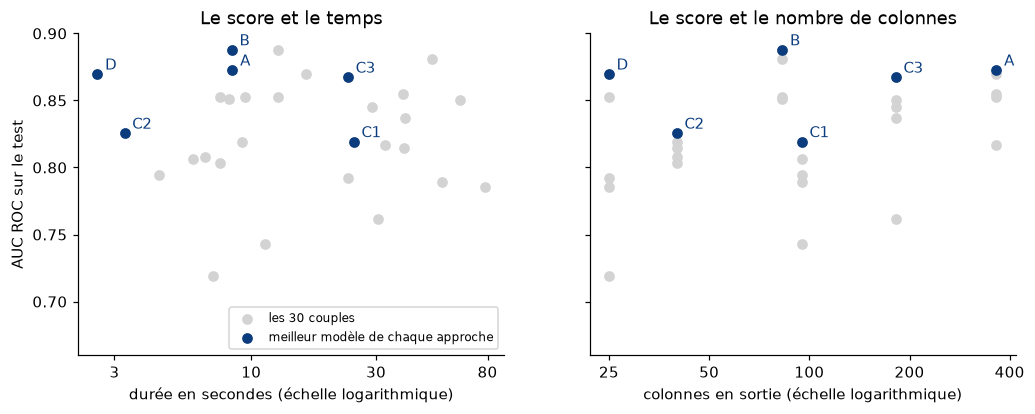

In [8]:
PANNEAUX = [("duree_s", "durée en secondes", [3, 10, 30, 80]),
            ("nb_variables", "colonnes en sortie", [25, 50, 100, 200, 400])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (colonne, titre, graduations) in zip(axes, PANNEAUX):
    ax.scatter(resultats[colonne], resultats["auc"], color="lightgrey", label="les 30 couples")
    ax.scatter(meilleurs[colonne], meilleurs["auc"], color=BLEU, label="meilleur modèle de chaque approche")
    for code, x, y in zip(meilleurs["code"], meilleurs[colonne], meilleurs["auc"]):
        ax.annotate(code, (x, y), xytext=(5, 3), textcoords="offset points", color=BLEU)
    ax.set(xscale="log", xlabel=f"{titre} (échelle logarithmique)", ylim=(0.66, 0.90))
    ax.minorticks_off()
    ax.set_xticks(graduations, [str(g) for g in graduations])
axes[0].set(ylabel="AUC ROC sur le test", title="Le score et le temps")
axes[1].set(title="Le score et le nombre de colonnes")
axes[0].legend(loc="lower right", fontsize=8)
plt.show()

Plus de colonnes ne veut pas dire un meilleur score : avec 83 colonnes, B fait mieux que A avec 365 et que C3 avec
182 ; avec 25, D fait presque jeu égal avec A. Côté temps, les boostings de D (2,6 s), de B (8,4 s) et de A
(8,5 s) sont parmi les plus rapides ; la sélection L1 de C3 multiplie la durée du boosting par près de trois
(23,4 s). Ces durées ont été mesurées par des notebooks différents, sur la même machine : seul leur ordre de
grandeur compte.

## 4. Les courbes ROC

Chaque appel à `evaluer` a aussi gardé les probabilités des cinq modèles pour les 24 018 réservations du test
(`output/probas_<code>.parquet`). On relit celles du meilleur modèle de chaque approche, après avoir vérifié que
les six fichiers portent bien la même cible, dans le même ordre que le test.

In [9]:
probas = {code: pd.read_parquet(SORTIES / f"probas_{code}.parquet") for code in meilleurs["code"]}
scores = pd.DataFrame({code: probas[code][modele] for code, modele in zip(meilleurs["code"], meilleurs["modele"])})
scores["y"] = probas["A"]["y"]
print("même cible dans les six fichiers :", all(p["y"].equals(scores["y"]) for p in probas.values()))
print("identique à la cible du test :", np.array_equal(scores["y"], test[CIBLE]))
scores.shape

même cible dans les six fichiers : True
identique à la cible du test : True


(24018, 7)

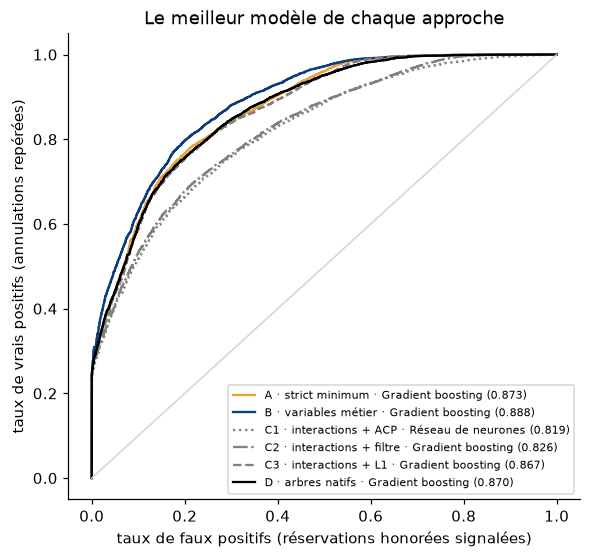

In [10]:
STYLES = {"A": (ORANGE, "-"), "B": (BLEU, "-"), "C1": ("grey", ":"), "C2": ("grey", "-."), "C3": ("grey", "--"),
          "D": ("black", "-")}
fig, ax = plt.subplots(figsize=(6, 5.5))
for approche, (code, modele, valeur) in meilleurs[["code", "modele", "auc"]].iterrows():
    fpr, tpr, _ = roc_curve(scores["y"], scores[code])
    couleur, trait = STYLES[code]
    ax.plot(fpr, tpr, color=couleur, linestyle=trait, label=f"{approche} · {modele} ({valeur:.3f})")
ax.plot([0, 1], [0, 1], color="lightgrey", linewidth=1)
ax.set(xlabel="taux de faux positifs (réservations honorées signalées)",
       ylabel="taux de vrais positifs (annulations repérées)", title="Le meilleur modèle de chaque approche")
ax.legend(fontsize=7.5, loc="lower right")
plt.show()

La courbe de B (en bleu) passe au-dessus des autres presque partout ; celles de A (orange) et de D (noir) se
confondent ; les trois variantes C (en gris) restent en dessous. Les courbes se resserrent aux deux extrémités : les
réservations les plus sûres et les plus risquées, tous les modèles les reconnaissent ; c'est dans le milieu que
la préparation fait la différence.

Une AUC se lit mal en salle de réunion. Traduisons : si l'hôtel appelait chaque semaine les 20 % de réservations
les plus risquées selon le modèle, combien de vraies annulations toucherait-il ?

In [11]:
k = int(0.2 * len(scores))
appel = {}
for code in meilleurs["code"]:
    reperees = scores["y"][scores[code].nlargest(k).index].sum()
    appel[code] = {"annulations parmi les appels": reperees, "part des appels utiles": reperees / k,
                   "part de toutes les annulations": reperees / scores["y"].sum()}
print(k, "réservations appelées sur", len(scores))
pd.DataFrame(appel).T.round(3).astype({"annulations parmi les appels": int})

4803 réservations appelées sur 24018


,annulations parmi les appels,part des appels utiles,part de toutes les annulations
A,4175,0.869,0.424
B,4332,0.902,0.440
C1,4060,0.845,0.412
C2,4068,0.847,0.413
C3,4155,0.865,0.422
D,4180,0.870,0.425


Sur 4 803 appels, le modèle de B tombe sur 4 332 annulations (90,2 % d'appels utiles), celui de A sur 4 175
(86,9 %) et celui de D sur 4 180 (87,0 %) : B en trouve 157 de plus que A, 152 de plus que D. C'est à cela que
correspond, concrètement, un écart d'AUC d'environ 0,015.

> 💬 **Pour la salle.** B ou D ? B gagne 0,018 d'AUC et environ 150 annulations repérées sur 4 803 appels ; D se
> contente de 25 colonnes brutes et d'un boosting entraîné en moins de 3 secondes. Lequel mettriez-vous en
> production ?
>
> *Piste : cela dépend de ce que rapporte une annulation repérée, et de ce que coûtent les variables de B. Les
> colonnes brutes de D sont connues dès la saisie ; B a besoin de l'historique à date de l'agent et du pays, qu'il
> faut calculer, stocker et servir à chaque réservation (section 5). Chaque variable a un coût (cours 2,
> slide 17) : le gain doit le payer.*

## 5. Le modèle retenu, face à de nouvelles réservations

On retient le gradient boosting de B. Le notebook 02 l'a sauvegardé **entier**, préparation comprise, avec
`joblib.dump` (cours 2, slide 24). On le recharge sans rien réentraîner, et on vérifie qu'il redonne les
probabilités enregistrées. Le modèle attend en entrée le tableau de `variables_metier`, pas les colonnes brutes.

In [12]:
modele = joblib.load(SORTIES / "modele_B.joblib")
v = variables_metier(df)
proba_B = modele.predict_proba(v.loc[test.index])[:, 1]
print(f"AUC du modèle rechargé : {roc_auc_score(test[CIBLE], proba_B):.4f}")
print(f"écart maximal avec probas_B.parquet : {np.abs(proba_B - scores['B']).max():.1e}")
modele

AUC du modèle rechargé : 0.8877
écart maximal avec probas_B.parquet : 3.0e-08


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modele', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](44,)","['nuits','part_nuits_week_end','personnes',...,'days_in_waiting_list', 'total_of_special_requests','is_repeated_guest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,44
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('asym', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).

Même AUC, 0,8877, et des probabilités identiques à 3·10⁻⁸ près (le fichier parquet les range en `float32`). Le
schéma rappelle ce que contient l'objet : les cinq branches de la préparation (avec les médianes, les λ de
Yeo-Johnson, les modalités du one-hot et les encodages par la cible appris sur le train), puis le boosting.

### 5.1 Trois nouvelles réservations

Le modèle est en service depuis le 22 avril 2017. Le 18 juin 2017, une réservation arrive pour le City Hotel ;
on prend celle du test qui porte le numéro 71658.

In [13]:
base = test[test["reservation_id"] == 71658]
base[["hotel", "date_reservation", "date_arrivee", "country", "agent", "market_segment", "deposit_type",
      "adults", "stays_in_weekend_nights", "stays_in_week_nights", "adr", CIBLE]].T

,110460
hotel,City Hotel
date_reservation,2017-06-18 00:00:00
date_arrivee,2017-07-09 00:00:00
country,FRA
agent,9
market_segment,Online TA
deposit_type,No Deposit
adults,2
stays_in_weekend_nights,2
stays_in_week_nights,2


Deux adultes, un client français passé par l'agent « 9 » (segment « Online TA », une agence en ligne), quatre
nuits du 9 juillet, dont deux de week-end, à un prix moyen de 130 par nuit (`adr`), sans acompte (« No Deposit »). On en fait trois « nouvelles » réservations : une copie
conforme, une où le pays devient `XKX` (le Kosovo, absent du fichier et du référentiel des pays), une où l'agent
devient `999` (un numéro qui n'existe pas). Une nouvelle réservation n'a pas encore d'issue : on retire la cible,
sa date de clôture et les colonnes de fuite.

In [14]:
nouvelles = pd.concat([base.drop(columns=FUITES + [CIBLE, "date_cloture"])] * 3, ignore_index=True)
nouvelles["reservation_id"] = df["reservation_id"].max() + np.arange(1, 4)
nouvelles["country"] = ["FRA", "XKX", "FRA"]
nouvelles["agent"] = ["9", "9", "999"]
nouvelles[["reservation_id", "date_reservation", "country", "agent", "lead_time", "adr"]]

,reservation_id,date_reservation,country,agent,lead_time,adr
0,119391,2017-06-18,FRA,9,21,130.0
1,119392,2017-06-18,XKX,9,21,130.0
2,119393,2017-06-18,FRA,999,21,130.0


Pour calculer leurs variables métier, la ligne seule ne suffit pas : le taux d'annulation à date de l'agent et du
pays demande **tout l'historique**, avec les issues des réservations passées. On ajoute donc les trois lignes aux
119 208 réservations connues, et on recalcule tout avec `variables_metier`.

In [15]:
historique = pd.concat([df, nouvelles], ignore_index=True)
v_nouvelles = variables_metier(historique).tail(3)
print(f"{len(historique):,} lignes pour calculer les variables de {len(nouvelles)} réservations".replace(",", " "))
v_nouvelles[["country", "continent", "membre_ue", "taux_annul_passe_country", "agent", "nb_resa_passees_agent",
             "nb_issues_connues_agent", "taux_annul_passe_agent"]].round(3)

119 211 lignes pour calculer les variables de 3 réservations


,country,continent,membre_ue,taux_annul_passe_country,agent,nb_resa_passees_agent,nb_issues_connues_agent,taux_annul_passe_agent
119208,FRA,Europe,1,0.193,9,31064.0,28799.0,0.443
119209,XKX,inconnu,0,NaN,9,31064.0,28799.0,0.443
119210,FRA,Europe,1,0.193,999,0.0,0.0,NaN


La copie conforme hérite de l'historique à date du 18 juin 2017 : 31 064 réservations passées pour l'agent 9,
dont 28 799 closes, avec un taux d'annulation de 0,443 ; un taux de 0,193 pour la France. Pour `XKX`, le
référentiel ne connaît pas le pays : continent « inconnu », pas membre de l'UE, aucun historique (taux NaN). Pour
l'agent 999 : aucune réservation passée, aucune issue connue, taux NaN. Le pipeline va-t-il planter ?

In [16]:
proba_origine = modele.predict_proba(v.loc[base.index])[0, 1]
proba_nouvelles = modele.predict_proba(v_nouvelles)[:, 1]
pd.DataFrame({"réservation": ["ligne 71658 du test, pour mémoire", "1 · copie conforme", "2 · pays jamais vu (XKX)",
                              "3 · agent jamais vu (999)"],
              "probabilité d'annulation": [proba_origine, *proba_nouvelles]}).round(3)

,réservation,probabilité d'annulation
0,"ligne 71658 du test, pour mémoire",0.474
1,1 · copie conforme,0.474
2,2 · pays jamais vu (XKX),0.706
3,3 · agent jamais vu (999),0.026


Il ne plante pas, et il répond trois choses différentes. La copie conforme reçoit exactement la probabilité de la
ligne d'origine (0,474) : les variables recalculées sont les mêmes, la préparation aussi. Le pays inconnu fait
monter la probabilité à 0,706 ; l'agent inconnu la fait tomber à 0,026. (Pour mémoire, cette réservation a
réellement été annulée.)

### 5.2 Ce que le pipeline a fait des inconnus

On regarde les colonnes concernées **après** la préparation, telles que le boosting les reçoit.

In [17]:
prep = modele["prep"]
apres = pd.DataFrame(prep.transform(v_nouvelles), columns=prep.get_feature_names_out(),
                     index=["1 · copie", "2 · XKX", "3 · agent 999"])
print("moyenne de la cible au train, retenue par le TargetEncoder :",
      round(prep.named_transformers_["forte_card"]["targetencoder"].target_mean_, 3))
apres[["forte_card__country", "cat__continent_inconnu", "num__missingindicator_taux_annul_passe_country",
       "forte_card__agent", "asym__nb_issues_connues_agent", "num__missingindicator_taux_annul_passe_agent"]].T.round(3)

moyenne de la cible au train, retenue par le TargetEncoder : 0.361


,1 · copie,2 · XKX,3 · agent 999
forte_card__country,-1.107,-0.001,-1.107
cat__continent_inconnu,0.000,1.000,0.000
num__missingindicator_taux_annul_passe_country,-0.242,4.131,-0.242
forte_card__agent,0.200,0.200,-0.001
asym__nb_issues_connues_agent,2.036,2.036,-1.776
num__missingindicator_taux_annul_passe_agent,-0.557,-0.557,1.795


Chaque inconnue a reçu une valeur prévue d'avance, apprise sur le train. Attention à la lecture : toutes ces
colonnes sont standardisées, les indicateurs de manquants compris.

- **Le pays `XKX`** : le `TargetEncoder` lui donne la moyenne de la cible sur tout le train (0,361), qui vaut
  −0,001 une fois standardisée, celle d'un pays « moyen » ; la France, qui annule moins, est à −1,107. Le one-hot
  le range dans `continent_inconnu` (1). L'indicateur de manquant du taux du pays passe de −0,242 à 4,131 : c'est
  le « 1 » d'un indicateur rare au train.
- **L'agent `999`** : même moyenne générale pour l'encodage par la cible (−0,001, contre 0,200 pour l'agent 9).
  `nb_issues_connues_agent` tombe de 2,036 à −1,776 (aucune issue connue, après Yeo-Johnson) et l'indicateur de
  manquant du taux de l'agent passe de −0,557 à 1,795.

Qu'est-ce qui fait chuter la troisième réservation : l'encodage de l'agent, ou son historique vide ? On change
l'un sans l'autre.

In [18]:
essais = {"agent 999, avec l'historique de l'agent 9": v_nouvelles.iloc[[0]].assign(agent="999"),
          "agent 9, avec un historique vide": v_nouvelles.iloc[[2]].assign(agent="9")}
pd.Series({nom: modele.predict_proba(x)[0, 1] for nom, x in essais.items()}).round(3).to_frame("probabilité")

,probabilité
"agent 999, avec l'historique de l'agent 9",0.486
"agent 9, avec un historique vide",0.026


C'est l'historique vide qui pèse : avec le seul encodage de l'agent changé, la probabilité bouge à peine (0,486
contre 0,474) ; avec le seul historique vidé, elle tombe à 0,026, exactement comme pour l'agent 999. Le modèle
répond avec ce que le train lui a appris des réservations « sans historique d'agent ». Ne pas planter n'est pas
prédire juste : ses réponses sont-elles raisonnables, en moyenne ? Le test contient de vraies réservations dans ce
cas.

In [19]:
v_test = v.loc[test.index]
groupes = {"agent sans réservation passée": v_test["agent"].notna() & (v_test["nb_resa_passees_agent"] == 0),
           "pays sans réservation passée": v_test["country"].notna() & (v_test["nb_resa_passees_country"] == 0)}
pd.DataFrame({nom: {"réservations": masque.sum(), "taux d'annulation réel": test.loc[masque, CIBLE].mean(),
                    "probabilité moyenne du modèle": proba_B[masque.to_numpy()].mean()}
              for nom, masque in groupes.items()}).T.round(3).astype({"réservations": int})

,réservations,taux d'annulation réel,probabilité moyenne du modèle
agent sans réservation passée,180,0.600,0.563
pays sans réservation passée,17,0.471,0.463


Sur les 180 réservations du test faites par un agent sans aucune réservation passée, le modèle prédit en moyenne
0,563 pour un taux réel de 0,600 ; sur les 17 réservations d'un pays sans passé, 0,463 pour 0,471. En moyenne, ses
réponses tiennent. Ligne par ligne, rien ne le garantit : une combinaison inédite, comme une réservation en ligne
ordinaire chez un agent sans aucun passé, peut recevoir une valeur extrême. En production, on surveille donc la
part des modalités inconnues et la justesse des prédictions sur ces lignes.

**Ce que cet exercice montre.** Le modèle tient dans un seul fichier, mais il ne suffit pas : pour noter trois
réservations, il a fallu relire les 119 208 réservations connues et leurs issues, puis tout recalculer. En
production, on ne recharge pas le fichier entier à chaque réservation : les historiques à date sont calculés à
l'avance, datés, stockés, et servis en quelques millisecondes, **les mêmes** à l'entraînement et en service.
C'est le rôle d'un *feature store* : le notebook 06 le met en place avec Feast.

> 💬 **Pour la salle.** `XKX` a été rangé dans le continent « inconnu », celui des 473 réservations du train
> *sans* pays, qui n'annulaient qu'à 11 % (notebook 02). Est-ce un bon choix ?
>
> *Piste : non. « Pays absent de la saisie » et « pays absent du référentiel » sont deux situations différentes,
> fondues ici par un `fillna("inconnu")`. Mieux vaut une modalité à part (« hors référentiel »), qui tombera dans
> la colonne des rares, et une alerte quand le référentiel ne connaît pas un code : une jointure est une hypothèse
> sur la qualité du référentiel.*

## 6. Ce que cette comparaison ne dit pas

Tous ces chiffres viennent d'**un seul découpage** (le 22 avril 2017), d'**un seul échantillon de test** (24 018
réservations), d'**un seul tirage** aléatoire (`random_state=0`) et de modèles **sans réglage**. Trois vérifications
rapides en donnent l'ordre de grandeur.

### 6.1 Un seul découpage : le score mois par mois

L'AUC sur le test est une moyenne sur quatre mois d'arrivées. Mois par mois, pour le meilleur modèle de chaque
approche :

In [20]:
NOMS_MOIS = {4: "avril (22-30)", 5: "mai", 6: "juin", 7: "juillet", 8: "août"}
scores["mois"] = test["date_arrivee"].dt.month.map(NOMS_MOIS).to_numpy()
par_mois = {}
for mois, groupe in scores.groupby("mois", sort=False):
    par_mois[mois] = {code: roc_auc_score(groupe["y"], groupe[code]) for code in meilleurs["code"]}
    par_mois[mois].update({"réservations": len(groupe), "taux d'annulation": groupe["y"].mean()})
pd.DataFrame(par_mois).T.round(3).astype({"réservations": int})

,A,B,C1,C2,C3,D,réservations,taux d'annulation
avril (22-30),0.930,0.933,0.873,0.912,0.924,0.932,1841,0.460
mai,0.907,0.921,0.870,0.875,0.907,0.900,6305,0.438
juin,0.882,0.896,0.833,0.840,0.876,0.877,5639,0.432
juillet,0.831,0.853,0.770,0.763,0.821,0.828,5310,0.374
août,0.821,0.839,0.747,0.752,0.814,0.829,4923,0.368


Le score baisse à mesure qu'on s'éloigne de la mise en service : pour B, de 0,933 pour les arrivées de fin avril
à 0,839 pour celles d'août ; pour A, de 0,930 à 0,821 ; pour D, de 0,932 à 0,829. B reste en tête chaque mois,
mais l'écart entre A et D change de signe d'un mois à l'autre (D devance A en avril et en août). Le taux
d'annulation lui-même bouge (de 46,0 % à 36,8 %). Un modèle vieillit : les
agents, les pays et les habitudes de réservation bougent. On le surveille, et on le réentraîne.

### 6.2 Un seul échantillon de test : le bootstrap

On tire 300 fois, avec remise, 24 018 réservations du test, et on recalcule l'écart d'AUC entre les boostings de
A, B et D. L'intervalle entre les quantiles 2,5 % et 97,5 % donne une idée de ce que le hasard de l'échantillon
peut faire.

In [21]:
rng = np.random.default_rng(0)
y, boostings = scores["y"].to_numpy(), {code: scores[code].to_numpy() for code in ["A", "B", "D"]}
ecarts = []
for _ in range(300):
    i = rng.integers(0, len(y), len(y))
    a = {code: roc_auc_score(y[i], s[i]) for code, s in boostings.items()}
    ecarts.append({"B − A": a["B"] - a["A"], "B − D": a["B"] - a["D"], "A − D": a["A"] - a["D"]})
pd.DataFrame(ecarts).quantile([0.025, 0.5, 0.975]).round(3)

,B − A,B − D,A − D
0.025,0.013,0.016,0.002
0.500,0.015,0.018,0.003
0.975,0.017,0.020,0.004


L'avance de B sur A (environ 0,015, entre 0,013 et 0,017) et sur D (environ 0,018, entre 0,016 et 0,020) résiste
au hasard de l'échantillon ; celle de A sur D aussi, mais elle est minuscule (environ 0,003). Prudence : les
réservations d'un même groupe ne sont pas indépendantes, et ce bootstrap les traite comme si elles l'étaient ; le
vrai intervalle est sans doute plus large.

### 6.3 Un seul tirage : d'autres graines

Le boosting tire au hasard son échantillon d'arrêt précoce, et le `TargetEncoder` ses plis. On réentraîne le
pipeline de B avec trois autres graines (environ une demi-minute).

In [22]:
X_train_B, X_test_B = v.loc[train.index], v.loc[test.index]
graines = {"graine 0 (modele_B.joblib)": roc_auc_score(test[CIBLE], proba_B)}
for graine in [1, 2, 3]:
    plis = StratifiedKFold(5, shuffle=True, random_state=graine)
    autre = clone(modele).set_params(modele__random_state=graine, prep__forte_card__targetencoder__cv=plis)
    autre.fit(X_train_B, train[CIBLE])
    graines[f"graine {graine}"] = roc_auc_score(test[CIBLE], autre.predict_proba(X_test_B)[:, 1])
pd.Series(graines).round(4).to_frame("AUC de B sur le test")

,AUC de B sur le test
graine 0 (modele_B.joblib),0.8877
graine 1,0.8898
graine 2,0.8886
graine 3,0.8886


Selon la graine, l'AUC de B va de 0,8877 à 0,8898 : environ 0,002 d'écart, et la graine du fichier est la moins
favorable des quatre. C'est peu devant l'avance de B sur A (environ 0,015), mais c'est autant, ou presque, que
l'écart entre A et D (environ 0,003) : ces deux-là, on ne sait pas vraiment les départager.

### 6.4 Pas de réglage, et un test qui a servi à choisir

Les cinq modèles gardent les mêmes réglages dans toutes les approches (50 voisins pour le kNN, 200 arbres pour la
forêt, les valeurs par défaut du boosting). Réglés pour chaque préparation, ils pourraient changer l'ordre des
approches proches, comme A et D (environ 0,003 d'écart pour le boosting). Le bon protocole : régler la préparation
et le modèle par validation croisée dans le temps, **à l'intérieur du train** (`TimeSeriesSplit`, `GridSearchCV`
sur `prep__cat__min_frequency`, cours 2, slide 24), puis mesurer une seule fois sur le test.

> 💬 **Pour la salle.** Nous avons choisi B en regardant les scores du test. L'AUC de 0,888 est-elle encore une
> estimation honnête de ce que B fera en production ?
>
> *Piste : plus tout à fait. En choisissant parmi trente scores celui qui est le plus haut, on a fait du test un
> jeu de validation : le meilleur score est un peu optimiste. Il faudrait un troisième jeu, jamais regardé (par
> exemple les arrivées de septembre 2017), ou choisir par validation croisée dans le train. Et la section 6.1
> rappelle que le score baissera de toute façon avec le temps.*

## À retenir

- **La préparation se choisit avec le modèle** : le kNN passe de 0,719 (D) à 0,853 (B) ; sur les mêmes 25 codes
  entiers, le boosting garde 0,870 (0,873 en A) quand la régression logistique tombe à 0,786 (0,853 en A). C'est la
  fiche réflexe du cours 2 (slide 28), mesurée.
- **Le métier paie** : les variables de B (historique à date, cycles, tranches, encodage par la cible) donnent la
  meilleure AUC à quatre modèles sur cinq, avec 83 colonnes. Générer sans hypothèse (C) ne bat jamais A, et l'ACP
  fait reculer tous les modèles.
- **Plus de colonnes n'est pas mieux** : 83 colonnes (B) battent 365 (A) ; 25 colonnes ordinales (D) suffisent au
  boosting pour égaler presque A. Chaque colonne a un coût, en calcul et en production.
- **Un modèle sauvegardé entier survit à la production** : pays et agent inconnus, taux manquants, rien ne
  plante. Mais ne pas planter n'est pas prédire juste, et ses variables d'historique ont besoin du passé : c'est le
  rôle du feature store (notebook 06).
- **Un écart se juge avec son incertitude** : B devance A d'environ 0,015 (de 0,013 à 0,017 par bootstrap) ; une
  autre graine déplace l'AUC d'environ 0,002, autant que l'écart entre A et D. Le tout sur un seul découpage, sans
  réglage, avec un test qui a servi à choisir, et un score qui baisse de mois en mois.